# 随机数序列的随机性检查

> 对应代码：`MathStatsCode/code_in_notes/Chap.5/check_random.do`（本 notebook 中的 Stata 代码与 do 文件一致）
>
> 运行方式：通过 *PyStata* 在 Jupyter 中调用 Stata，安装与使用说明见 `notebook/PyStata.md`。

**实验目的**：把生成的随机数按行号奇偶分成两组，用散点图直观检查两列随机数是否无规律、相互独立。

**说明**：为在 notebook 中直接内联显示图形，本 notebook 的 Stata 代码省略了 `.do` 文件中的 `graph export` 导出命令（`code_in_notes` 中对应的 .do 文件保留导出，用于生成书中的插图）。

首先启动 Stata 环境，并把工作目录切换到 `code_in_notes/Chap.5`，这样 Stata 中的相对路径（如 `../datasets/...`）与同名 do 文件完全一致，图片也会输出到该目录。


In [1]:
# 配置 PyStata：启动 Stata 并注册 %%stata 魔法命令
import os
os.chdir("../../code_in_notes/Chap.5")

import stata_setup
stata_setup.config("/opt/Stata", "mp")


  ___  ____  ____  ____  ____ ®
 /__    /   ____/   /   ____/      Stata 18.0
___/   /   /___/   /   /___/       MP—Parallel Edition

 Statistics and Data Science       Copyright 1985-2023 StataCorp LLC
                                   StataCorp
                                   4905 Lakeway Drive
                                   College Station, Texas 77845 USA
                                   800-782-8272        https://www.stata.com
                                   979-696-4600        service@stata.com

Stata license: Single-user 16-core  perpetual
Serial number: 501806307019
  Licensed to: Keep calm and DO your research
               Jichun Si

Notes:
      1. Unicode is supported; see help unicode_advice.
      2. More than 2 billion observations are allowed; see help obs_advice.
      3. Maximum number of variables is set to 5,000 but can be increased;
          see help set_maxvar.


准备一个含1000个观测的数据集（`set more off` 关闭分页、`clear` 清空内存、`set obs 1000` 设定观测数），并用 `set seed 890907` 设定随机数种子：种子固定后每次运行产生的随机数序列完全相同，保证本实验的结果可以复现。


In [2]:
%%stata
set more off
clear
set obs 1000
set seed 890907



. set more off

. clear

. set obs 1000
Number of observations (_N) was 0, now 1,000.

. set seed 890907

. 


**行号是奇数还是偶数**

用观测的行号构造分组变量：`_n` 是 Stata 内置的当前观测序号；`mod(_n,2)` 取余数，把行号分为奇数（1）和偶数（0）；`group=ceil(_n/2)` 把 (1,2)、(3,4)… 这样的相邻两行编为同一组，为下一步“宽型”变换做准备。


In [3]:
%%stata
gen variable_id=mod(_n,2)
gen group=ceil(_n/2)



. gen variable_id=mod(_n,2)

. gen group=ceil(_n/2)

. 


**产生序贯的随机数**

`gen x=runiform()`：生成一列1000个均匀分布随机数。此时它们只是依次排列的一个序列。


In [4]:
%%stata
gen x=runiform()


**将奇数观测作为x1，偶数观测作为x0**

`reshape wide x, i(group) j(variable_id)`：长宽变换。按 group 配对、按 variable_id 拆列，原来的单列 x 被拆成两列：x1（奇数列）和 x0（偶数列）。这样每一行就是相邻产生的一对随机数。


In [5]:
%%stata
reshape wide x, i(group) j(variable_id)


(j = 0 1)

Data                               Long   ->   Wide
-----------------------------------------------------------------------------
Number of observations            1,000   ->   500         
Number of variables                   3   ->   3           
j variable (2 values)       variable_id   ->   (dropped)
xij variables:
                                      x   ->   x0 x1
-----------------------------------------------------------------------------


**画散点图**

`scatter x1 x0`：把相邻两个随机数画成散点图。如果随机数生成器正常，x1 与 x0 应当**独立**——点云应均匀散布在单位正方形内、看不出任何规律或聚集（若出现条纹、空洞等结构，说明随机数序列存在缺陷）。`graphr(fcolor(white) color(white))` 把绘图区和外围背景都设为白色。


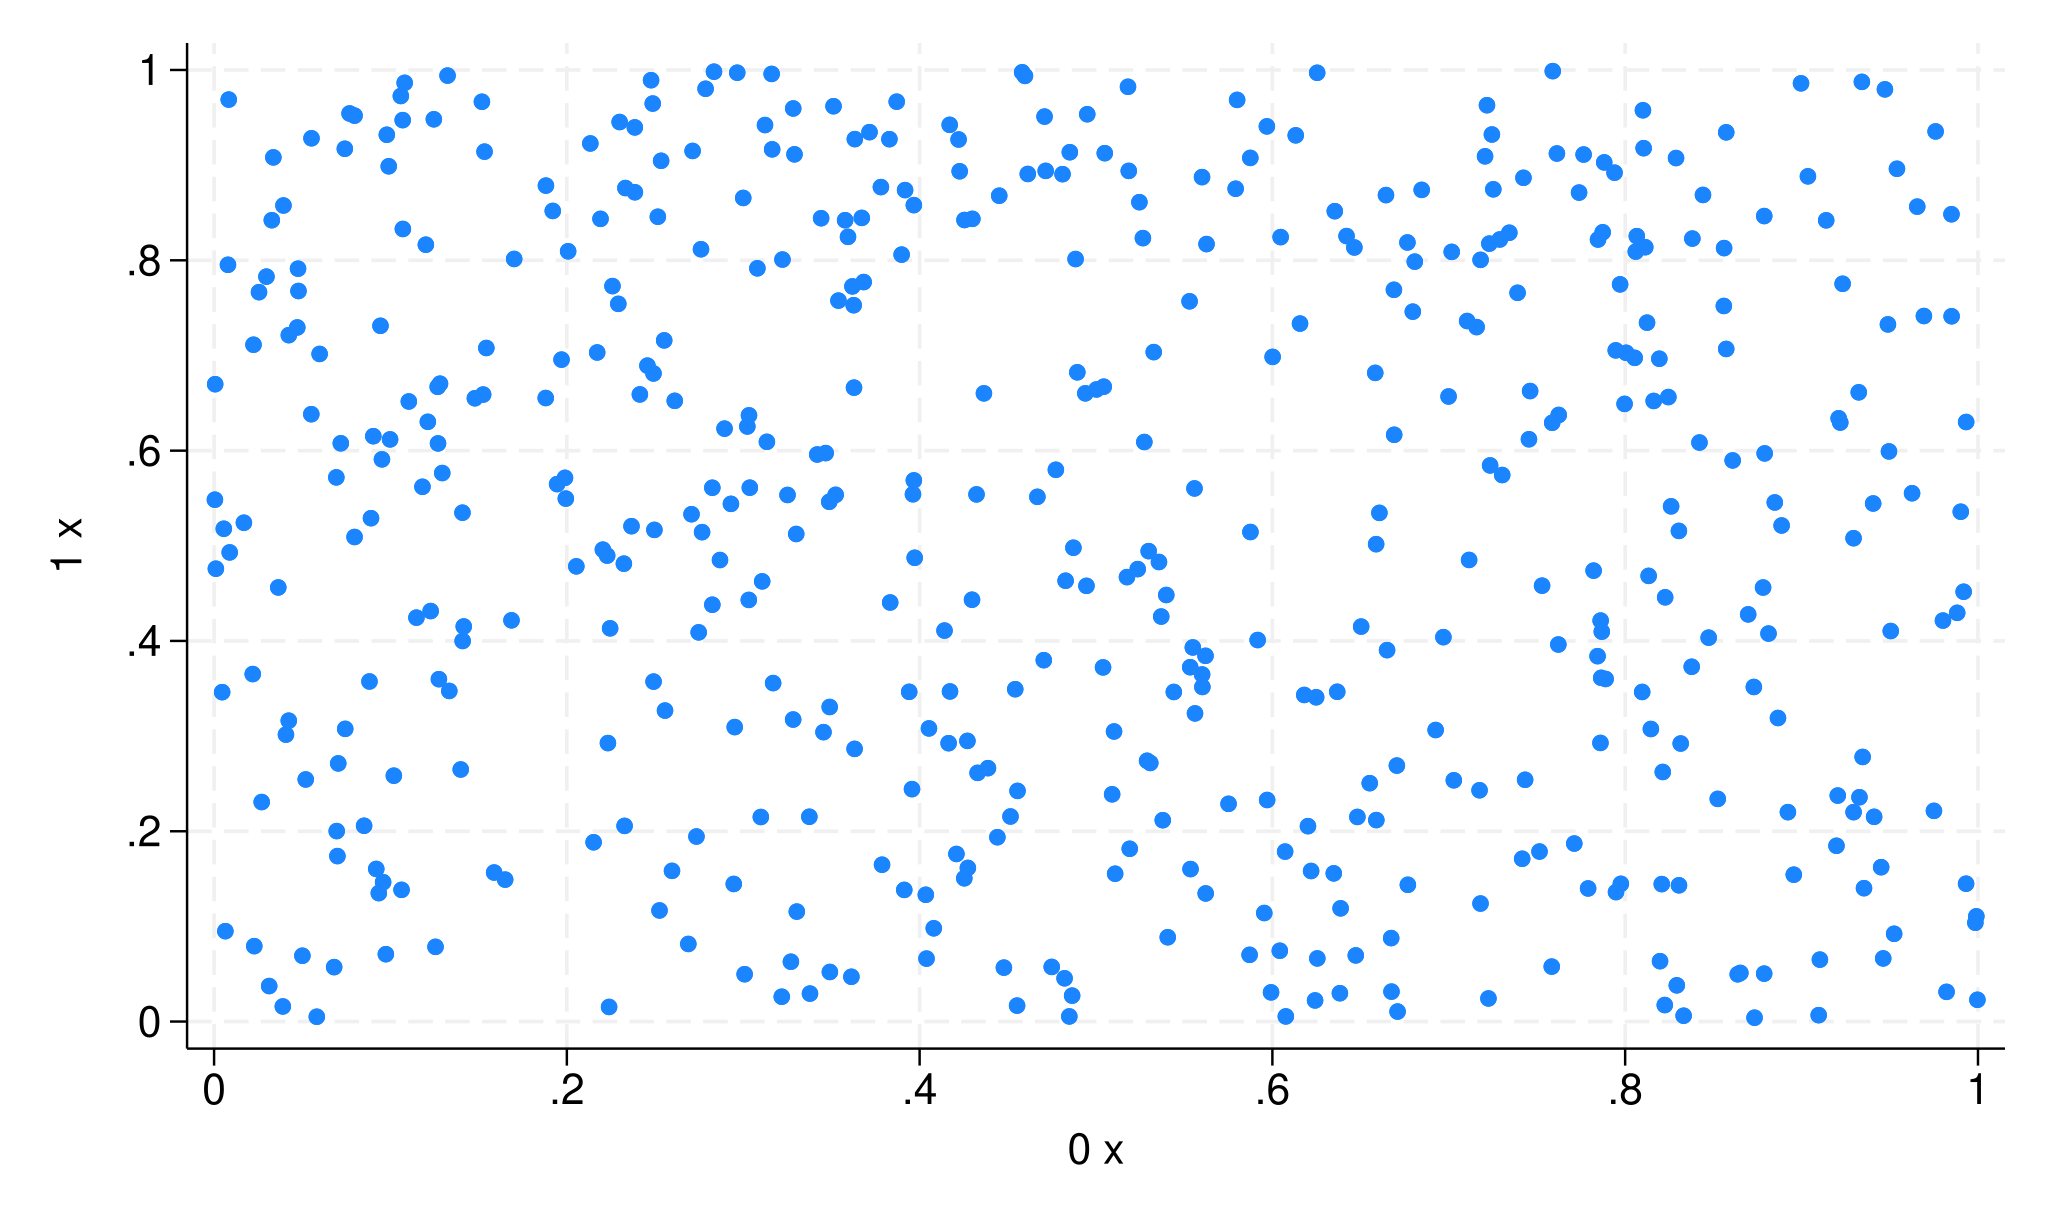

In [6]:
%%stata
scatter x1 x0 ,  graphr(fcolor(white) color(white))


**保存图片**

`graph export`：把图形导出为 PDF 文件（`replace` 表示若文件已存在则覆盖）。导出前不需要保留图形窗口，方便批量生成图片供讲义使用。
